# Week 2 — Exploratory Data Analysis and Visualization
## Understanding Bank Marketing Campaign Outcomes

**Objective:** Explore customer profiles, campaign patterns and term-deposit subscription outcomes using Pandas, Matplotlib and Seaborn. This notebook generates annotated plots and summary tables suitable for a report.


In [2]:

import io, zipfile, urllib.request, warnings, os, json, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"

def extract_bank_full(zip_bytes):
    """Find bank-full.csv even when it is nested in an inner ZIP."""
    with zipfile.ZipFile(io.BytesIO(zip_bytes)) as zf:
        for name in zf.namelist():
            if Path(name).name.lower() == "bank-full.csv":
                return zf.read(name)
        for name in zf.namelist():
            if name.lower().endswith(".zip"):
                try:
                    found = extract_bank_full(zf.read(name))
                    if found:
                        return found
                except (zipfile.BadZipFile, KeyError):
                    pass
    return None

def load_bank_marketing():
    archive = urllib.request.urlopen(DATA_URL, timeout=60).read()
    csv_bytes = extract_bank_full(archive)
    if csv_bytes is None:
        raise FileNotFoundError("Could not find bank-full.csv in the official UCI archive.")
    data = pd.read_csv(io.BytesIO(csv_bytes), sep=";", keep_default_na=False)
    data.columns = [c.strip().lower() for c in data.columns]
    return data

df_raw = load_bank_marketing()
print("Dataset shape:", df_raw.shape)
display(df_raw.head())


Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 1. Prepare analysis features

Normalize category strings, map the target to a binary indicator for calculations, create customer-age bands and campaign-contact bands, and interpret `pdays = -1` as no prior contact. We retain `duration` for descriptive EDA because it is part of the observed campaign record, but it will not be used in pre-call predictive modelling.


In [3]:
df = df_raw.copy()
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].str.strip().str.lower()
df["subscribed"] = (df["y"] == "yes").astype(int)
df["age_group"] = pd.cut(df["age"], bins=[17,25,35,45,55,65,100],
                         labels=["18–25","26–35","36–45","46–55","56–65","66+"])
df["campaign_band"] = pd.cut(df["campaign"], bins=[0,1,2,3,5,100],
                             labels=["1","2","3","4–5","6+"])
df["prior_contact"] = np.where(df["pdays"] == -1, "No prior contact", "Previously contacted")
print("Shape:", df.shape)
print("Subscription rate:", round(df["subscribed"].mean()*100, 2), "%")
display(df.describe(include="all").T)


Shape: (45211, 21)
Subscription rate: 11.7 %


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,45211.0,NaN,NaN,NaN,40.93621,10.618762,18.0,33.0,39.0,48.0,95.0
job,45211,12,blue-collar,9732,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,45211,3,married,27214,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,45211,4,secondary,23202,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,45211,2,no,44396,NaN,NaN,NaN,NaN,NaN,NaN,NaN
balance,45211.0,NaN,NaN,NaN,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
housing,45211,2,yes,25130,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,45211,2,no,37967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,45211,3,cellular,29285,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day,45211.0,NaN,NaN,NaN,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0


## 2. Outcome distribution and class imbalance

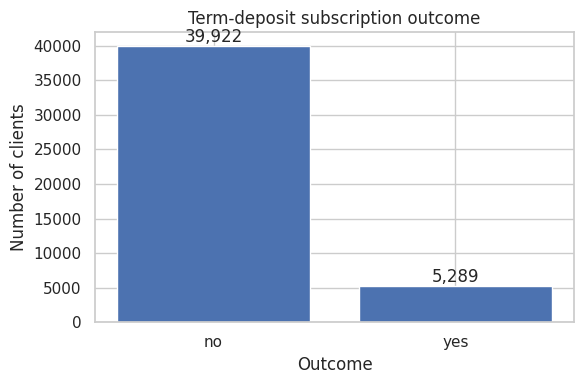

,count,percent
y,,
no,39922,88.3
yes,5289,11.7


In [4]:
counts = df["y"].value_counts().reindex(["no","yes"])
fig, ax = plt.subplots(figsize=(6,4))
bars = ax.bar(counts.index, counts.values)
ax.set(title="Term-deposit subscription outcome", xlabel="Outcome", ylabel="Number of clients")
for b, v in zip(bars, counts.values):
    ax.text(b.get_x()+b.get_width()/2, v, f"{v:,}", ha="center", va="bottom")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"count": counts, "percent": (counts/len(df)*100).round(2)}))


## 3. Customer profile: age and job

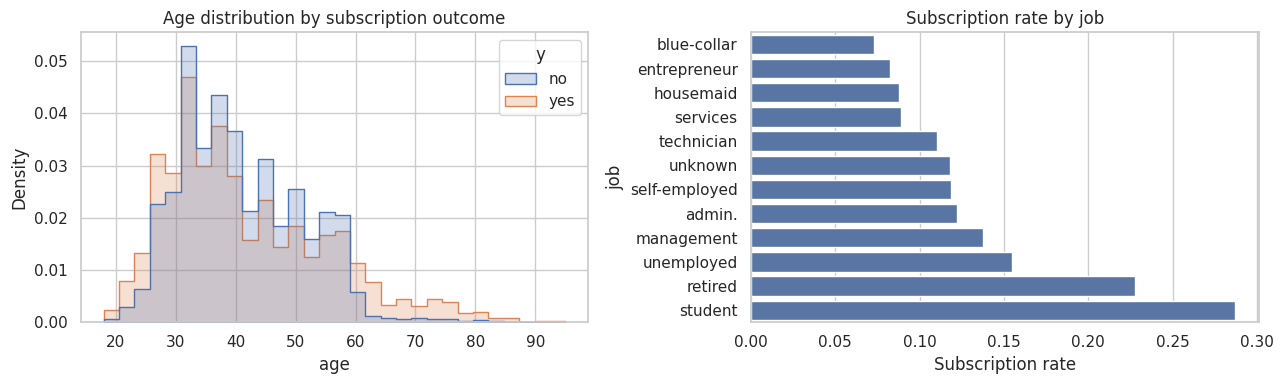

,count,mean
job,,
student,938,0.287
retired,2264,0.228
unemployed,1303,0.155
management,9458,0.138
admin.,5171,0.122
self-employed,1579,0.118
unknown,288,0.118
technician,7597,0.111
services,4154,0.089


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13,4))
sns.histplot(data=df, x="age", hue="y", bins=30, stat="density",
             common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Age distribution by subscription outcome")
job_rate = df.groupby("job", observed=False)["subscribed"].mean().sort_values()
sns.barplot(x=job_rate.values, y=job_rate.index, ax=axes[1])
axes[1].set_title("Subscription rate by job")
axes[1].set_xlabel("Subscription rate")
plt.tight_layout(); plt.show()
display((df.groupby("job")["subscribed"].agg(["count","mean"]).sort_values("mean", ascending=False)).round(3))


## 4. Education, marital status and financial indicators

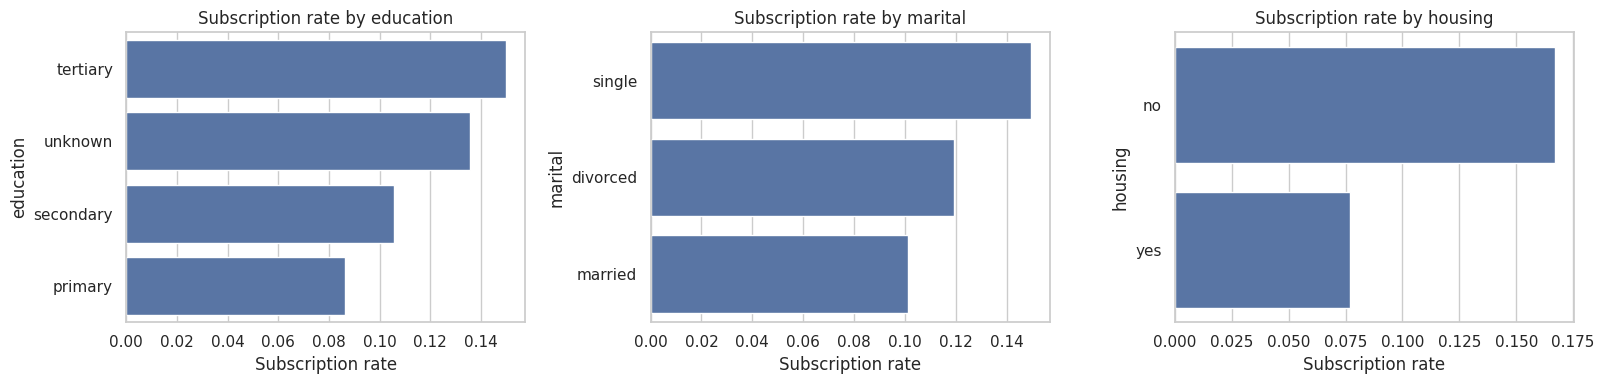

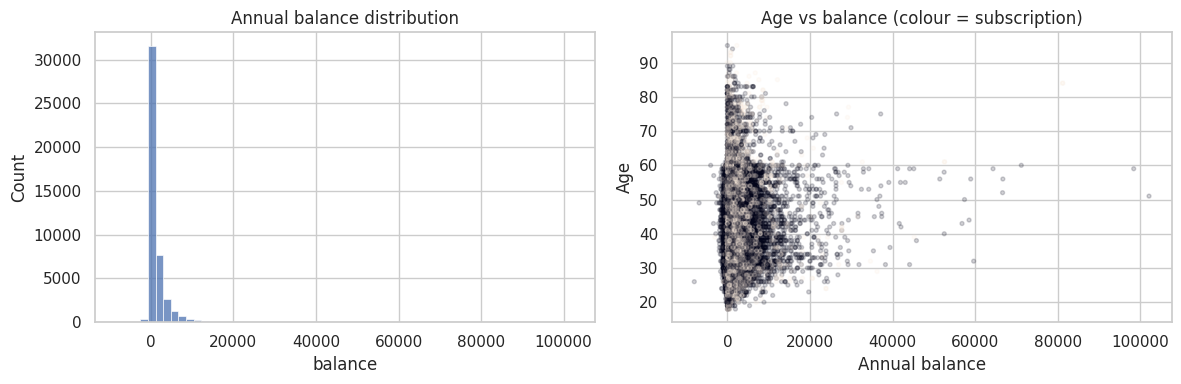

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for col, ax in zip(["education","marital","housing"], axes):
    rate = df.groupby(col)["subscribed"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax)
    ax.set_title(f"Subscription rate by {col}")
    ax.set_xlabel("Subscription rate")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.histplot(data=df, x="balance", bins=60, ax=axes[0])
axes[0].set_title("Annual balance distribution")
axes[1].scatter(df["balance"], df["age"], c=df["subscribed"], alpha=.18, s=8)
axes[1].set_title("Age vs balance (colour = subscription)")
axes[1].set_xlabel("Annual balance"); axes[1].set_ylabel("Age")
plt.tight_layout(); plt.show()


## 5. Campaign timing and previous campaign history

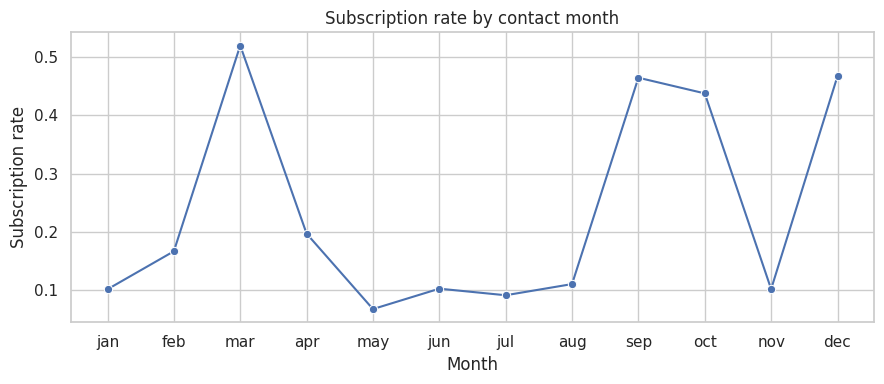

,count,mean
poutcome,,
success,1511,0.647
other,1840,0.167
failure,4901,0.126
unknown,36959,0.092


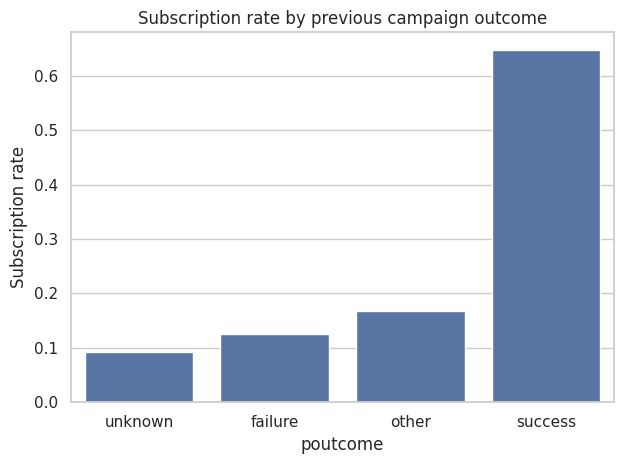

In [7]:
month_order = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
monthly = df.groupby("month")["subscribed"].mean().reindex(month_order)
plt.figure(figsize=(9,4))
sns.lineplot(x=monthly.index, y=monthly.values, marker="o")
plt.title("Subscription rate by contact month")
plt.xlabel("Month"); plt.ylabel("Subscription rate")
plt.tight_layout(); plt.show()

pout = df.groupby("poutcome")["subscribed"].agg(["count","mean"]).sort_values("mean", ascending=False)
display(pout.round(3))
sns.barplot(data=df, x="poutcome", y="subscribed", estimator=np.mean, errorbar=None)
plt.title("Subscription rate by previous campaign outcome")
plt.ylabel("Subscription rate"); plt.tight_layout(); plt.show()


## 6. Number of contacts, call duration and correlation

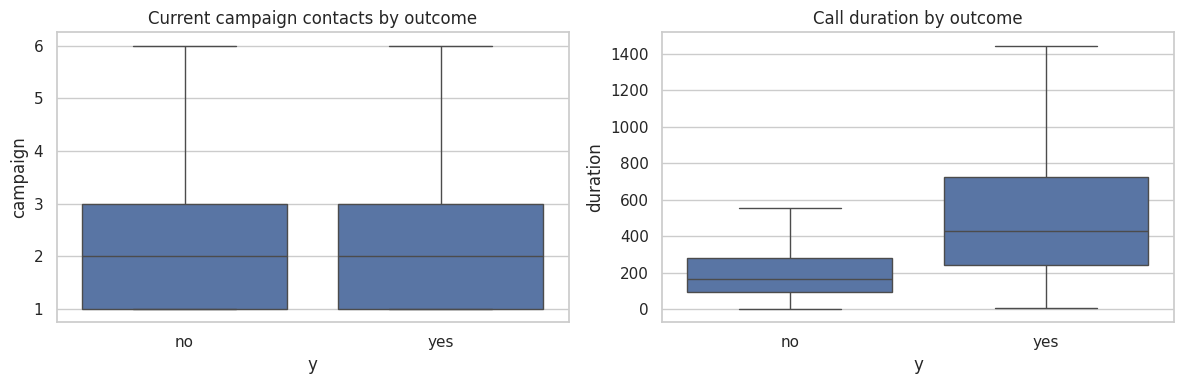

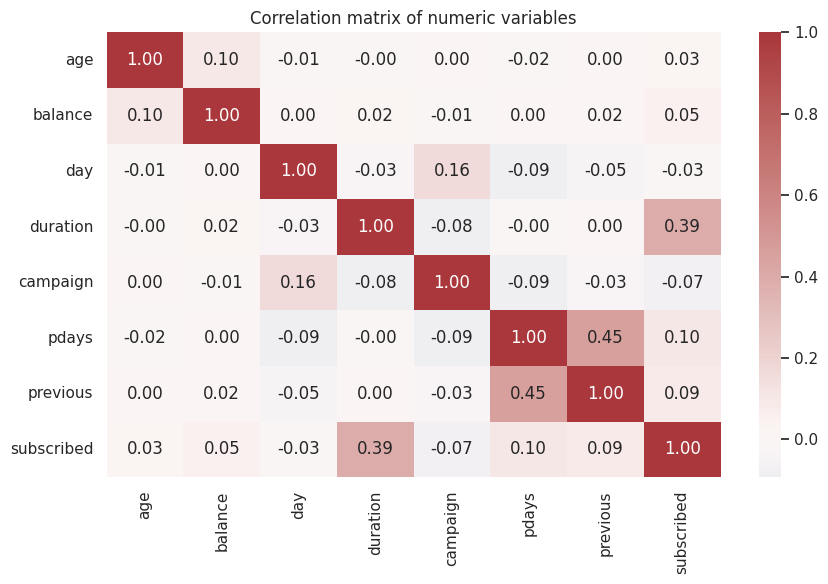

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=df, x="y", y="campaign", showfliers=False, ax=axes[0])
axes[0].set_title("Current campaign contacts by outcome")
sns.boxplot(data=df, x="y", y="duration", showfliers=False, ax=axes[1])
axes[1].set_title("Call duration by outcome")
plt.tight_layout(); plt.show()

numeric = ["age","balance","day","duration","campaign","pdays","previous","subscribed"]
plt.figure(figsize=(9,6))
sns.heatmap(df[numeric].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation matrix of numeric variables")
plt.tight_layout(); plt.show()


## 7. Findings and interpretation

Use the output tables and plots to support the written findings. Compare both subscription rates and subgroup sample sizes: a high rate in a small group may be unstable. The class imbalance means the overall percentage subscribed is much lower than the percentage not subscribed. Do not infer causation from group differences or correlations.

The `duration` plot may show a strong association with the outcome, but duration is measured during the call and is unavailable before calling a customer. It is therefore useful for retrospective process analysis, not for a realistic pre-call targeting model. `poutcome` and previous contact information may also reflect historic campaign processes rather than intrinsic customer propensity.


In [9]:
# Save figures manually from the notebook if your report needs image files:
# Example: plt.savefig("figure_name.png", dpi=200, bbox_inches="tight")
print("EDA complete. Record key rates and counts from the displayed tables.")


EDA complete. Record key rates and counts from the displayed tables.
